# San Francisco Housing Production and Family Zoning Plan

## Imports — all in one place

In [13]:
import json
import urllib.request
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns


<a id="step-1"></a>
## Step 1 — Clean and filter the data

### 1a. Housing Production: select the study period
Read the raw Housing Production CSV, preserve permit and parcel IDs as text, and convert first completion dates to dates. Keep dates from January 1, 2005 through December 31, 2025 and known, nonzero net unit changes. Retain negative changes because housing losses belong in a net-additions measure. Rename the six fields expected by the teammate workflow; the resulting table is named housing_production_filtered. Unmatched permits will remain in the study sample.


In [14]:
housing = pd.read_csv("data/raw/housing_production.csv", dtype={"bpa": str, "blocklot": str})
housing

,source_row_id,bpa,address,description,pts_existing_units,pts_proposed_units,proposed_units,net_units,net_units_completed,adu_legalization_units,...,plan_area,form_no,permit_type,issued_date,authorization_date,zoning_district,project_affordability_type,bmr_reporting_year,blocklot,ppts_project_id
0,row-uj95-csqk.dju3,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,...,NaN,3,Site Permit,2007-04-27T00:00:00.000,2007-04-27T00:00:00.000,P,NaN,2010,1300001,NaN
1,row-ntav.j4q3-gvpk,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-29T11:30:17.000,RH-2,NaN,2008,5828012,2007.0150
2,row-8kwi~kmki~667e,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-29T10:59:39.000,RH-2,NaN,2008,5828011,NaN
3,row-knk4~b77d~zswv,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,...,NaN,2,Site Permit,2004-08-31T00:00:00.000,2004-09-01T11:41:51.000,RH-2,NaN,2005,1855045,2003.0545
4,row-6snx-hhan_j82j,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,...,NaN,2,Full Building Permit,2005-01-05T00:00:00.000,2005-01-05T00:00:00.000,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6155,row-xxzz~wz7e~g8r7,9924082S,871 JAMESTOWN AV,BLDG #6 - ERECT A 3 STORIES OF EIGHTEEN UNITS ...,0,18.0,18,18,18,0,...,NaN,2,Site Permit,2006-03-28T00:00:00.000,2006-08-16T12:07:27.000,RH-2,100% Affordable,2014,4991277,1999.233
6156,row-xf6x_ve62.znz9,9925758S,981 GREENWICH ST,ERECT A THREE STORY THREE UNIT RESIDENTIAL BLDG,0,3.0,3,3,3,0,...,NaN,2,Site Permit,2001-08-02T00:00:00.000,2001-08-03T16:56:26.000,RM-1,NaN,2005,0092044,2002.0792
6157,row-xh2y~5vmg-x6ue,9927159S,380 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-31T14:21:57.000,RH-2,NaN,2008,5828013,2007.0151
6158,row-c84k_ck9c~rb8t,Academe 198,198 McAllister St,SF Law graduate student housing – Majority of ...,0,NaN,657,657,657,0,...,NaN,1,Full Building Permit,NaN,2023-02-01T00:00:00.000,P,NaN,2023,0348009,2025-008348PRX


In [15]:
# Housing Produciton data cleaning

# covert to datetime & numeric
housing["first_completion_date"] = pd.to_datetime(housing["first_completion_date"])
housing["net_units_completed"] = pd.to_numeric(housing["net_units_completed"])

# Keep the study period, known nonzero changes, and all housing losses.
in_period = (housing["first_completion_date"] >= "2005-01-01") & (housing["first_completion_date"] < "2026-01-01")
valid_units = (~housing["net_units_completed"].isna()) & (housing["net_units_completed"] != 0)

selected = housing.loc[in_period & valid_units].copy()

# rename each column
housing_production_filtered = selected.rename(columns={
    "bpa": "BPA", 
    "address": "Address", 
    "blocklot": "BlockLot",
    "net_units_completed": "Net Units Completed",
    "first_completion_date": "First Completion Date", "latest_completion_date": "Latest Completion Date"
})

In [16]:
# save filtered housing production dta as csv file

housing_production_filtered.to_csv("data/processed/housing_production_filtered.csv", index=False)

print("Study records:", len(housing_production_filtered))
print("Source net housing additions:", housing_production_filtered["Net Units Completed"].sum())

housing_production_filtered


Study records: 5981
Source net housing additions: 57982


,source_row_id,BPA,Address,description,pts_existing_units,pts_proposed_units,proposed_units,net_units,Net Units Completed,adu_legalization_units,...,plan_area,form_no,permit_type,issued_date,authorization_date,zoning_district,project_affordability_type,bmr_reporting_year,BlockLot,ppts_project_id
0,row-uj95-csqk.dju3,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,...,NaN,3,Site Permit,2007-04-27T00:00:00.000,2007-04-27T00:00:00.000,P,NaN,2010,1300001,NaN
1,row-ntav.j4q3-gvpk,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-29T11:30:17.000,RH-2,NaN,2008,5828012,2007.0150
2,row-8kwi~kmki~667e,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-29T10:59:39.000,RH-2,NaN,2008,5828011,NaN
3,row-knk4~b77d~zswv,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,...,NaN,2,Site Permit,2004-08-31T00:00:00.000,2004-09-01T11:41:51.000,RH-2,NaN,2005,1855045,2003.0545
4,row-6snx-hhan_j82j,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,...,NaN,2,Full Building Permit,2005-01-05T00:00:00.000,2005-01-05T00:00:00.000,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6155,row-xxzz~wz7e~g8r7,9924082S,871 JAMESTOWN AV,BLDG #6 - ERECT A 3 STORIES OF EIGHTEEN UNITS ...,0,18.0,18,18,18,0,...,NaN,2,Site Permit,2006-03-28T00:00:00.000,2006-08-16T12:07:27.000,RH-2,100% Affordable,2014,4991277,1999.233
6156,row-xf6x_ve62.znz9,9925758S,981 GREENWICH ST,ERECT A THREE STORY THREE UNIT RESIDENTIAL BLDG,0,3.0,3,3,3,0,...,NaN,2,Site Permit,2001-08-02T00:00:00.000,2001-08-03T16:56:26.000,RM-1,NaN,2005,0092044,2002.0792
6157,row-xh2y~5vmg-x6ue,9927159S,380 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,NaN,2,Site Permit,2006-08-29T00:00:00.000,2006-08-31T14:21:57.000,RH-2,NaN,2008,5828013,2007.0151
6158,row-c84k_ck9c~rb8t,Academe 198,198 McAllister St,SF Law graduate student housing – Majority of ...,0,NaN,657,657,657,0,...,NaN,1,Full Building Permit,NaN,2023-02-01T00:00:00.000,P,NaN,2023,0348009,2025-008348PRX


### 1b. Land Use cleaning — adapted directly from `clean_sf_land_use.py`

This section adapts the cleaning rules in clean_sf_land_use.py directly into the notebook. Flag missing parcel IDs and residential-unit values; remove unusable IDs, remove thousands separators, and apply the original missing-value treatment. Keep the teammate's ten parcel-conflict decisions and deduplicate parcel IDs. The project uses the published centroid fields, so it does not repair or export unused Land Use polygons or derive unused control variables. Land Use residential units are not treated as historical 2008 or 2005 stock.


In [17]:
land = pd.read_csv("data/raw/San_Francisco_Land_Use.csv",dtype={"mapblklot": str, "residential_units": str}, low_memory=False)
land

,the_geom,LUDB_id,centroid_latitude,centroid_longitude,residential_units,residential_units_special,cie,med,mips,retail,...,parking_lot,garage,open_space,residential_use,geography_type,mapblklot,major_multiphase_project,special_jurisdiction,data_as_of,data_loaded_at
0,"MULTIPOLYGON (((-122.388813 37.78295, -122.389...",DAGid_0_20260817,37.783644,-122.388816,177,0,0,0,0,59221,...,False,False,False,NaN,multiple_parcels,"'3791002', '3791001', '3790001'",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
1,"MULTIPOLYGON (((-122.388513 37.784828, -122.38...",DAGid_1_20260817,37.784916,-122.389736,863,0,0,0,0,0,...,False,False,False,NaN,multiple_parcels,"'3773577', '3773300A', '3773291', '3773200A', ...",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
2,"MULTIPOLYGON (((-122.420419 37.805374, -122.42...",DAGid_2_20260817,37.805473,-122.420596,24,0,0,0,0,0,...,False,False,False,NaN,multiple_parcels,"'0026T001A', '0026028'",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
3,"MULTIPOLYGON (((-122.431644 37.782376, -122.43...",DAGid_3_20260817,37.782041,-122.431272,120,0,0,0,0,0,...,False,False,False,NaN,multiple_parcels,"'0732001', '0732002', '0732004', '0732028', '0...",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
4,"MULTIPOLYGON (((-122.421594 37.780454, -122.42...",DAGid_4_20260817,37.780507,-122.421121,0,0,0,0,270768,0,...,False,False,False,NaN,multiple_parcels,"'0767005', '0767009', '0767007', '0767001', '0...",NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
153760,"MULTIPOLYGON (((-122.389035869 37.720764617, -...",DAGid_165198_20260817,37.720837,-122.388865,2,0,0,0,0,0,...,False,False,False,NaN,parcel,4909002,NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
153761,"MULTIPOLYGON (((-122.463917797 37.711180579, -...",DAGid_165200_20260817,37.711214,-122.464091,3,0,0,0,0,0,...,False,False,False,NaN,parcel,7135022,NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
153762,"MULTIPOLYGON (((-122.503286888 37.764168657, -...",DAGid_165201_20260817,37.764139,-122.503185,2,0,0,0,0,0,...,False,False,False,NaN,parcel,1707001,NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM
153763,"MULTIPOLYGON (((-122.404650526 37.780491839, -...",DAGid_165202_20260817,37.780605,-122.404704,8,0,0,0,0,0,...,False,False,False,NaN,parcel,3732096,NaN,NaN,08/17/2026 12:00:00 AM,08/17/2026 12:00:00 AM


In [18]:
# Flag missing fields before applying the original cleaning rule.
land["missing_parcel_id"] = land["mapblklot"].isna()
land["missing_residential_units"] = land["residential_units"].isna()
land = land.loc[~land["missing_parcel_id"]].copy()
land["residential_units"] = land["residential_units"].fillna("0")
clean_unit_values = []
for value in land["residential_units"]:
    clean_unit_values.append(int(value.replace(",", "")))
land["residential_units"] = clean_unit_values

# Retain the original teammate's parcel-conflict decisions.
AUDIT_RETAIN = {
    "1761053": 2, "3180214": 71, "6310010": 69, "6310011": 108,
    "6311014": 4, "6311016": 170, "6311026": 4, "7138055": 1,
    "4285B003": 1, "4285B004": 157
}
for parcel_id, retained_units in AUDIT_RETAIN.items():
    remove = (land["mapblklot"] == parcel_id) & (land["residential_units"] != retained_units)
    land = land.loc[~remove].copy()
land = land.drop_duplicates(subset="mapblklot", keep="first")
land = land[["mapblklot", "centroid_latitude", "centroid_longitude", "residential_units","geography_type", "missing_parcel_id", "missing_residential_units"]]

Cleaned Land Use records: 153754


In [20]:
# save filtered land as sf_land_use_clean.csv
land.to_csv("data/processed/sf_land_use_clean.csv", index=False)
print("Cleaned Land Use records:", len(land))

land.head()

Cleaned Land Use records: 153754


,mapblklot,centroid_latitude,centroid_longitude,residential_units,geography_type,missing_parcel_id,missing_residential_units
0,"'3791002', '3791001', '3790001'",37.783644,-122.388816,177,multiple_parcels,False,False
1,"'3773577', '3773300A', '3773291', '3773200A', ...",37.784916,-122.389736,863,multiple_parcels,False,False
2,"'0026T001A', '0026028'",37.805473,-122.420596,24,multiple_parcels,False,False
3,"'0732001', '0732002', '0732004', '0732028', '0...",37.782041,-122.431272,120,multiple_parcels,False,False
4,"'0767005', '0767009', '0767007', '0767001', '0...",37.780507,-122.421121,0,multiple_parcels,False,False


<a id="step-2"></a>
## Step 2 — Give each permit a location

### 2a. Exact individual-parcel join — from `tabular_join.py`

Select Land Use rows marked parcel and left-merge Housing Production BlockLot with Land Use mapblklot. Copy the published latitude and longitude, while retaining every housing record. Only coordinates are attached; Land Use stock is never added to permit-level net unit changes.


In [23]:
single = land.loc[
    land["geography_type"] == "parcel", ["mapblklot", "centroid_latitude", "centroid_longitude"]
].rename(columns={"centroid_latitude": "latitude", "centroid_longitude": "longitude"})
located = housing_production_filtered.merge(single, left_on="BlockLot", right_on="mapblklot", how="left")
located = located.drop(columns="mapblklot")
single_match = (~located["latitude"].isna()) & (~located["longitude"].isna())
located["match_status"] = "unmatched"
located["match_note"] = "no_parcel_match"
located.loc[single_match, "match_status"] = "matched_single"
located.loc[single_match, "match_note"] = "parcel_centroid"


### 2b. Read the fully quoted IDs in multi-parcel entries — from `tabular_join.py`

This preserves the multi-parcel rules in tabular_join.py using classroom string indexing, lists, loops and conditional statements instead of regular expressions. Read only fully quoted IDs. At least two complete IDs are required, and a malformed fragment is accepted only at the end; the fragment itself is never used. Reject IDs from invalid lists or conflicting locations. Prefer a complete-list source when the same coordinate is repeated. Fill only permits not already located by the individual-parcel merge.


In [24]:
multi = land.loc[land["geography_type"] == "multiple_parcels"].copy()
multi["has_coordinates"] = (~multi["centroid_latitude"].isna()) & (~multi["centroid_longitude"].isna())
multi_rows = []
unsafe_ids = []
letters_and_digits = "ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz0123456789"

for raw, latitude, longitude, has_coordinates in zip(multi["mapblklot"], multi["centroid_latitude"], multi["centroid_longitude"], multi["has_coordinates"]):
    raw = raw.strip()
    parts = []
    part = ""
    for character in raw:
        if character == ",":
            parts.append(part.strip())
            part = ""
        else:
            part = part + character
    parts.append(part.strip())

    # Collect all fully quoted IDs, including IDs in a rejected list.
    quoted_ids = []
    inside_quote = False
    fragment = ""
    for character in raw:
        if character == "'":
            if inside_quote:
                valid_id = len(fragment) > 0
                for letter in fragment:
                    if letter not in letters_and_digits:
                        valid_id = False
                if valid_id:
                    quoted_ids.append(fragment)
            inside_quote = not inside_quote
            fragment = ""
        elif inside_quote:
            fragment = fragment + character

    parcel_ids = []
    valid_list = True
    partial_source = False
    for position, part in enumerate(parts):
        complete = len(part) >= 3 and part[0] == "'" and part[-1] == "'"
        if complete:
            for letter in part[1:-1]:
                if letter not in letters_and_digits:
                    complete = False
        if complete:
            parcel_ids.append(part[1:-1])
        else:
            trailing_partial = len(part) >= 2 and part[0] == "'"
            if trailing_partial:
                for letter in part[1:]:
                    if letter not in letters_and_digits:
                        trailing_partial = False
            allowed_tail = position == len(parts) - 1 and len(parcel_ids) >= 2 and (part == "" or trailing_partial)
            if allowed_tail:
                partial_source = True
            else:
                valid_list = False
    if len(parcel_ids) < 2:
        valid_list = False
    if valid_list and has_coordinates:
        for parcel_id in parcel_ids:
            multi_rows.append([parcel_id, latitude, longitude, partial_source])
    else:
        unsafe_ids.extend(quoted_ids)

multi_candidates = pd.DataFrame(
    multi_rows, columns=["BlockLot", "candidate_latitude", "candidate_longitude", "partial_source"]
)
multi_candidates = multi_candidates.sort_values("partial_source")
multi_candidates = multi_candidates.drop_duplicates(subset=["BlockLot", "candidate_latitude", "candidate_longitude"])
multi_counts = multi_candidates.groupby("BlockLot").size().to_frame(name="candidate_locations")
multi_candidates = multi_candidates.merge(multi_counts, on="BlockLot", how="left")
for parcel_id in multi_candidates.loc[multi_candidates["candidate_locations"] > 1, "BlockLot"]:
    unsafe_ids.append(parcel_id)
multi_candidates = multi_candidates.loc[
    (multi_candidates["candidate_locations"] == 1) & (~multi_candidates["BlockLot"].isin(unsafe_ids))
].copy()
multi_candidates = multi_candidates.sort_values("partial_source").drop_duplicates(subset="BlockLot")


In [25]:
# Fill only records not located by the individual-parcel join.
located = located.merge(
    multi_candidates[["BlockLot", "candidate_latitude", "candidate_longitude", "partial_source"]],
    on="BlockLot", how="left"
)
fill = (located["match_status"] == "unmatched") & (~located["candidate_latitude"].isna()) & (~located["candidate_longitude"].isna())
located.loc[fill, "latitude"] = located.loc[fill, "candidate_latitude"]
located.loc[fill, "longitude"] = located.loc[fill, "candidate_longitude"]
located.loc[fill, "match_status"] = "matched_multi_centroid"
located.loc[fill, "match_note"] = "shared_group_centroid_not_individual_parcel"
located.loc[fill & (located["partial_source"] == True), "match_note"] = "shared_group_centroid;partial_source_id_list"
located.loc[(located["match_status"] == "unmatched") & located["BlockLot"].isin(unsafe_ids), "match_note"] = "unsafe_multi_parcel_list_or_conflict"
located = located.drop(columns=["candidate_latitude", "candidate_longitude", "partial_source"])

In [26]:
# save located file as housing_production_located.csv
located.to_csv("data/processed/housing_production_located.csv", index=False)
located.head()

,source_row_id,BPA,Address,description,pts_existing_units,pts_proposed_units,proposed_units,net_units,Net Units Completed,adu_legalization_units,...,authorization_date,zoning_district,project_affordability_type,bmr_reporting_year,BlockLot,ppts_project_id,latitude,longitude,match_status,match_note
0,row-uj95-csqk.dju3,1801Wedemeyer,1801 Wedemeyer St,PRESIDIO LANDMARK 100 1-BR; 54 2-BR (Federal l...,0,NaN,154,154,154,0,...,2007-04-27T00:00:00.000,P,NaN,2010,1300001,NaN,NaN,NaN,unmatched,no_parcel_match
1,row-ntav.j4q3-gvpk,20000109571,360 BENTON AV,"TO ERECT A NEW 3 STORY, 2 UNIT RESIDENTIAL BUI...",0,2.0,2,2,2,0,...,2006-08-29T11:30:17.000,RH-2,NaN,2008,5828012,2007.0150,NaN,NaN,unmatched,no_parcel_match
2,row-8kwi~kmki~667e,20000112863,340 BENTON AV,TO ERECT A NEW 3 STORY 2 FAMILY DWELLING RESID...,0,2.0,2,2,2,0,...,2006-08-29T10:59:39.000,RH-2,NaN,2008,5828011,NaN,NaN,NaN,unmatched,no_parcel_match
3,row-knk4~b77d~zswv,20000112908,505 KIRKHAM ST,ERECT 4 STORY 2 FAMILY DWELLING UNIT,0,2.0,2,2,2,0,...,2004-09-01T11:41:51.000,RH-2,NaN,2005,1855045,2003.0545,NaN,NaN,unmatched,no_parcel_match
4,row-6snx-hhan_j82j,20000118277,1810 POLK ST,"TO ERECT 12 DWELLING UNITS, 4 STORIES, RESIDEN...",0,12.0,12,12,12,0,...,2005-01-05T00:00:00.000,NCD-POLK,Incl: On-Site BMR,2006,0597016,2000.051,NaN,NaN,unmatched,no_parcel_match


### 2c. Supplement missing coordinates

This project-specific recovery section preserves all Land Use locations and follows the established fallback order. It constructs every comparison key and candidate table from raw inputs during this run. A left merge retains all housing records; candidate uniqueness is calculated before any coordinate is copied.


In [27]:
# Preserve the team's original match labels.
located["team_match_status"] = located["match_status"]
located["team_match_note"] = located["match_note"]
located["location_source"] = "unlocated"
located.loc[located["match_status"] == "matched_single", "location_source"] = "land_use_single"
located.loc[located["match_status"] == "matched_multi_centroid", "location_source"] = "land_use_group_centroid"

# Start the additional source-description columns as empty text.
for column in ["source_point_type", "source_parcel_id", "location_note", "parcel_reference_active"]:
    located[column] = ""
located.loc[located["match_status"] == "matched_single", "source_point_type"] = "Land Use parcel centroid"
located.loc[located["match_status"] == "matched_multi_centroid", "source_point_type"] = "Land Use group centroid"
located.loc[located["match_status"] != "unmatched", "source_parcel_id"] = located["BlockLot"]


### 2c-1. Generate the housing address keys

从 `located` 已有的 `Address` 和 `BlockLot` 生成比较字段，不再按 BPA 读取旧的地址键文件。函数使用 Lab 3 的 strip/upper、索引与 Lab 4 的循环，把连续空白合成一个空格，按完整单词统一 AVENUE/AVE、STREET，同时保留标点、门牌与单元信息。Assessor block 是地块号开头四位数字加可选字母。

The comparison keys are derived from this run's housing rows. Normalize capitalization, whitespace and whole-word suffixes without regex; retain punctuation, house numbers and unit information. Extract the assessor block from the original parcel ID. The resulting address_keys.csv is an output, not a prerequisite.


In [28]:
# Normalize addresses using Lab 3 string methods and Lab 4 loops.
def normalize_address(address):
    text = str(address).strip().upper()
    collapsed = ""
    previous_space = False
    for character in text:
        if character in " \t\r\n\v\f":
            if not previous_space:
                collapsed = collapsed + " "
            previous_space = True
        else:
            collapsed = collapsed + character
            previous_space = False

    # Replace whole words, keeping punctuation and unit information.
    normalized = ""
    word = ""
    word_characters = "ABCDEFGHIJKLMNOPQRSTUVWXYZ0123456789_"
    for character in collapsed + " ":
        if character in word_characters:
            word = word + character
        else:
            if word == "AVE" or word == "AVENUE":
                word = "AV"
            if word == "STREET":
                word = "ST"
            normalized = normalized + word + character
            word = ""
    return normalized.strip()

# Derive comparison keys from this run's housing rows, not from an existing file.
address_keys = []
assessor_blocks = []
for address, parcel_id in zip(located["Address"], located["BlockLot"]):
    address_keys.append(normalize_address(address))
    parcel_text = str(parcel_id)
    valid_block = len(parcel_text) >= 4
    for character in parcel_text[:4]:
        if character not in "0123456789":
            valid_block = False
    if valid_block:
        block = parcel_text[:4]
        if len(parcel_text) > 4 and parcel_text[4] in "ABCDEFGHIJKLMNOPQRSTUVWXYZ":
            block = parcel_text[:5]
        assessor_blocks.append(block)
    else:
        assessor_blocks.append(np.nan)
located["address_key"] = address_keys
located["assessor_block"] = assessor_blocks
located["address_block_key"] = located["address_key"] + "|" + located["assessor_block"]
located[["BPA", "address_key", "assessor_block", "address_block_key"]].to_csv(
    "data/processed/address_keys.csv", index=False
)


### 2c-2. Expand raw DBI JSON

Use the JSON-reading pattern in Lab 6 on a local raw file. Flatten every DBI record into ordinary columns before applying any primary-address or uniqueness rule. Missing coordinates remain missing. dbi_coordinates.csv is created by this notebook, not loaded as a prepared input.


In [29]:
# Read the downloaded raw JSON using the JSON-reading pattern from Lab 6.
# file: means a local file; this cell does not query the internet.
with urllib.request.urlopen("file:data/raw/dbi_all_study_permit_coordinates.json") as response:
    dbi_records = json.loads(response.read())

# Put each raw record into ordinary table columns before choosing any candidate.
dbi_rows = []
for record in dbi_records:
    latitude = np.nan
    longitude = np.nan
    if "location" in record and record["location"] is not None:
        longitude = record["location"]["coordinates"][0]
        latitude = record["location"]["coordinates"][1]
    dbi_rows.append([
        record["permit_number"], record["block"], record["lot"],
        record.get("primary_address_flag", ""), latitude, longitude,
        record.get("point_source", "")
    ])
dbi = pd.DataFrame(dbi_rows, columns=[
    "permit_number", "block", "lot", "primary_address_flag", "latitude", "longitude", "point_source"
])
dbi.to_csv("data/processed/dbi_coordinates.csv", index=False)

# Keep complete primary-address coordinates and preserve the existing matching rule.
dbi = dbi.loc[
    (dbi["primary_address_flag"] == "Y") &
    (~dbi["latitude"].isna()) & (~dbi["longitude"].isna())
].copy()
dbi["source_parcel_id"] = dbi["block"] + dbi["lot"]
dbi = dbi.rename(columns={
    "permit_number": "BPA", "latitude": "candidate_latitude", "longitude": "candidate_longitude",
    "point_source": "candidate_point_type", "source_parcel_id": "candidate_parcel_id"
})


In [30]:
# Count distinct candidate locations for each BPA.
dbi = dbi.drop_duplicates(subset=["BPA", "candidate_latitude", "candidate_longitude"])
candidate_counts = dbi.groupby("BPA").size().to_frame(name="candidate_locations")
dbi = dbi.merge(candidate_counts, on="BPA", how="left")

# Accept one location only; do not arbitrarily choose between different locations.
dbi = dbi.loc[dbi["candidate_locations"] == 1].copy()


In [31]:
# A left merge retains every housing record.
located = located.merge(dbi[['BPA', 'candidate_latitude', 'candidate_longitude', 'candidate_point_type', 'candidate_parcel_id']], on="BPA", how="left")

# Fill only missing locations with an available candidate coordinate.
needs_location = located["latitude"].isna() | located["longitude"].isna()
fill = needs_location & (~located["candidate_latitude"].isna()) & (~located["candidate_longitude"].isna())
located.loc[fill, "latitude"] = located.loc[fill, "candidate_latitude"]
located.loc[fill, "longitude"] = located.loc[fill, "candidate_longitude"]
located.loc[fill, "source_point_type"] = located.loc[fill, "candidate_point_type"]
located.loc[fill, "source_parcel_id"] = located.loc[fill, "candidate_parcel_id"]
located.loc[fill, "location_source"] = "dbi_primary"
located.loc[fill, "location_note"] = "Exact permit ID; one unique located primary coordinate"

# Remove temporary candidate columns before reading the next source.
located = located.drop(columns=['candidate_latitude', 'candidate_longitude', 'candidate_point_type', 'candidate_parcel_id'])


### 2c-3. Read the original recorded-parcel CSV 

Read the original flat CSV directly. Match the exact historic parcel ID and accept only one unique published centroid; retain its active flag and reference-centroid label. No precomputed lookup table is supplied.


In [40]:
parcels = pd.read_csv(
    "data/raw/parcel_dated.csv",
    dtype={"blklot": str, "mapblklot": str}
)
parcels = parcels.loc[
    (~parcels["centroid_latitude"].isna()) & (~parcels["centroid_longitude"].isna())
].copy()
parcels["candidate_point_type"] = "DPW recorded parcel centroid"
parcels["candidate_parcel_id"] = parcels["blklot"]
parcels["candidate_active"] = parcels["active"].astype(str)
parcels = parcels.rename(columns={
    "blklot": "BlockLot", "centroid_latitude": "candidate_latitude",
    "centroid_longitude": "candidate_longitude"
})


In [41]:
# Count distinct candidate locations for each BlockLot.
parcels = parcels.drop_duplicates(subset=["BlockLot", "candidate_latitude", "candidate_longitude"])
candidate_counts = parcels.groupby("BlockLot").size().to_frame(name="candidate_locations")
parcels = parcels.merge(candidate_counts, on="BlockLot", how="left")

# Accept one location only; do not arbitrarily choose between different locations.
parcels = parcels.loc[parcels["candidate_locations"] == 1].copy()


In [42]:
# A left merge retains every housing record.
located = located.merge(parcels[['BlockLot', 'candidate_latitude', 'candidate_longitude', 'candidate_point_type', 'candidate_parcel_id', 'candidate_active']], on="BlockLot", how="left")

# Fill only missing locations with an available candidate coordinate.
needs_location = located["latitude"].isna() | located["longitude"].isna()
fill = needs_location & (~located["candidate_latitude"].isna()) & (~located["candidate_longitude"].isna())
located.loc[fill, "latitude"] = located.loc[fill, "candidate_latitude"]
located.loc[fill, "longitude"] = located.loc[fill, "candidate_longitude"]
located.loc[fill, "source_point_type"] = located.loc[fill, "candidate_point_type"]
located.loc[fill, "source_parcel_id"] = located.loc[fill, "candidate_parcel_id"]
located.loc[fill, "parcel_reference_active"] = located.loc[fill, "candidate_active"]
located.loc[fill, "location_source"] = "recorded_parcel_centroid"
located.loc[fill, "location_note"] = "Exact blklot; published reference centroid, not a surveyed building point"

# Remove temporary candidate columns before reading the next source.
located = located.drop(columns=['candidate_latitude', 'candidate_longitude', 'candidate_point_type', 'candidate_parcel_id', 'candidate_active'])


### 2c-4. Build address candidates from raw JSON

Flatten the saved raw address records, build the street address from its three components, and normalize it with the same function used for housing. Combine it with the candidate block. The later merge requires an exact address/block key and one unique location; existing coordinates are preserved.


In [47]:
# Read every saved raw address candidate; no candidate is accepted in advance.
with urllib.request.urlopen("file:data/raw/same_address_location_candidates.json") as response:
    address_records = json.loads(response.read())
address_rows = []
for record in address_records:
    street_address = str(record.get("street_number", "")) + " " + str(record.get("street_name", "")) + " " + str(record.get("street_suffix", ""))
    latitude = np.nan
    longitude = np.nan
    if "location" in record and record["location"] is not None:
        longitude = record["location"]["coordinates"][0]
        latitude = record["location"]["coordinates"][1]
    address_rows.append([
        record["permit_number"], record["block"], record["lot"], street_address,
        latitude, longitude, record.get("point_source", ""), normalize_address(street_address)
    ])
addresses = pd.DataFrame(address_rows, columns=[
    "permit_number", "block", "lot", "candidate_street_address", "latitude", "longitude", "point_source", "address_key"
])
addresses["address_block_key"] = addresses["address_key"] + "|" + addresses["block"]
addresses.to_csv("data/processed/address_candidates.csv", index=False)
addresses = addresses.loc[(~addresses["latitude"].isna()) & (~addresses["longitude"].isna())].copy()
addresses["source_parcel_id"] = addresses["block"] + addresses["lot"]
addresses = addresses.rename(columns={
    "latitude": "candidate_latitude", "longitude": "candidate_longitude",
    "point_source": "candidate_point_type", "source_parcel_id": "candidate_parcel_id"
})


In [48]:
# Count distinct candidate locations for each address_block_key.
addresses = addresses.drop_duplicates(subset=["address_block_key", "candidate_latitude", "candidate_longitude"])
candidate_counts = addresses.groupby("address_block_key").size().to_frame(name="candidate_locations")
addresses = addresses.merge(candidate_counts, on="address_block_key", how="left")

# Accept one location only; do not arbitrarily choose between different locations.
addresses = addresses.loc[addresses["candidate_locations"] == 1].copy()


In [49]:
# A left merge retains every housing record.
located = located.merge(addresses[['address_block_key', 'candidate_latitude', 'candidate_longitude', 'candidate_point_type', 'candidate_parcel_id']], on="address_block_key", how="left")

# Fill only missing locations with an available candidate coordinate.
needs_location = located["latitude"].isna() | located["longitude"].isna()
fill = needs_location & (~located["candidate_latitude"].isna()) & (~located["candidate_longitude"].isna())
located.loc[fill, "latitude"] = located.loc[fill, "candidate_latitude"]
located.loc[fill, "longitude"] = located.loc[fill, "candidate_longitude"]
located.loc[fill, "source_point_type"] = located.loc[fill, "candidate_point_type"]
located.loc[fill, "source_parcel_id"] = located.loc[fill, "candidate_parcel_id"]
located.loc[fill, "location_source"] = "same_address_same_block"
located.loc[fill, "location_note"] = "Exact normalized address and assessor block; candidates agree on one point"

# Remove temporary candidate columns before reading the next source.
located = located.drop(columns=['candidate_latitude', 'candidate_longitude', 'candidate_point_type', 'candidate_parcel_id'])


### 2c-5. Expand the saved Census responses 

Read every saved response and retain request/response evidence before filtering. Extract the street portion with a loop, normalize both addresses identically, and accept only a unique San Francisco street-address match. Keep the approximate address-range provenance label.


In [53]:
# Read saved raw Census responses and retain the original matched street address.
with urllib.request.urlopen("file:data/raw/census2020_geocoded_remaining_addresses.json") as response:
    census_responses = json.loads(response.read())
census_rows = []
for requested_address, response in census_responses.items():
    matches = response["result"]["addressMatches"]
    for match in matches:
        matched_street = ""
        before_comma = True
        for character in match["matchedAddress"]:
            if character == ",":
                before_comma = False
            if before_comma:
                matched_street = matched_street + character
        census_rows.append([
            requested_address, match["matchedAddress"], normalize_address(requested_address),
            normalize_address(matched_street), match["addressComponents"]["city"], len(matches),
            match["coordinates"]["y"], match["coordinates"]["x"]
        ])
census = pd.DataFrame(census_rows, columns=[
    "requested_address", "matched_address", "address_key", "matched_address_key", "city", "match_count", "latitude", "longitude"
])
census.to_csv("data/processed/census_candidates.csv", index=False)

# The notebook, rather than a prepared table, decides which matches are acceptable.
census = census.loc[
    (census["match_count"] == 1) & (census["city"] == "SAN FRANCISCO") &
    (census["address_key"] == census["matched_address_key"])
].copy()
census = census.rename(columns={"latitude": "candidate_latitude", "longitude": "candidate_longitude"})


In [54]:
# Count distinct candidate locations for each address_key.
census = census.drop_duplicates(subset=["address_key", "candidate_latitude", "candidate_longitude"])
candidate_counts = census.groupby("address_key").size().to_frame(name="candidate_locations")
census = census.merge(candidate_counts, on="address_key", how="left")

# Accept one location only; do not arbitrarily choose between different locations.
census = census.loc[census["candidate_locations"] == 1].copy()


In [55]:
# A left merge retains every housing record.
located = located.merge(census[['address_key', 'candidate_latitude', 'candidate_longitude']], on="address_key", how="left")

# Fill only missing locations with an available candidate coordinate.
needs_location = located["latitude"].isna() | located["longitude"].isna()
fill = needs_location & (~located["candidate_latitude"].isna()) & (~located["candidate_longitude"].isna())
located.loc[fill, "latitude"] = located.loc[fill, "candidate_latitude"]
located.loc[fill, "longitude"] = located.loc[fill, "candidate_longitude"]
located.loc[fill, "source_point_type"] = "Public_AR_Census2020 address range"
located.loc[fill, "location_source"] = "census_address_range"
located.loc[fill, "location_note"] = "Approximate address-range coordinate; unique exact normalized street-address match"

# Remove temporary candidate columns before reading the next source.
located = located.drop(columns=['candidate_latitude', 'candidate_longitude'])


In [56]:
# Update only records recovered from the originally unmatched set.
recovered = (
    (located["team_match_status"] == "unmatched") &
    (~located["latitude"].isna()) & (~located["longitude"].isna())
)
located.loc[recovered, "match_status"] = "matched_supplemental"
located.loc[recovered, "match_note"] = located.loc[recovered, "location_source"] + ": " + located.loc[recovered, "location_note"]

# Remove the comparison keys generated earlier in this run from the finished housing table.
located = located.drop(columns=["address_key", "assessor_block", "address_block_key"])


In [57]:
located.to_csv("data/processed/housing_production_located_recovered.csv", index=False)
location_sources = located.groupby("location_source")["Net Units Completed"].agg(["count", "sum"])
location_sources.to_csv("data/processed/location_source_summary.csv")
location_sources


,count,sum
location_source,,
census_address_range,10,-66
dbi_primary,1984,38348
land_use_group_centroid,37,2672
land_use_single,3938,16136
recorded_parcel_centroid,10,908
same_address_same_block,2,-16


<a id="step-3"></a>
## Step 3 — Assign housing records to 2020 census tracts

This section implements the tract_aggregation.py method directly: create EPSG:4326 housing points, spatially join them to 2020 tract polygons using a left within join, and merge the GEOID back by permit ID. The tract GeoJSON is now an original download from the same DataSF dataset, not an assistant-converted file. Preserve every permit, including any unassigned records. Report both record counts and net units at the Land Use-only and recovered stages.


In [60]:
tracts = gpd.read_file("data/raw/census_2020_tracts_raw.geojson")
tracts = tracts.rename(columns={"geoid": "GEOID", "name": "NAME"})
has_coordinates = (~located["latitude"].isna()) & (~located["longitude"].isna())
point_features = []
for permit_id, longitude, latitude in zip(
    located.loc[has_coordinates, "BPA"], located.loc[has_coordinates, "longitude"], located.loc[has_coordinates, "latitude"]
):
    point_features.append({
        "type": "Feature", "properties": {"BPA": permit_id},
        "geometry": {"type": "Point", "coordinates": [longitude, latitude]}
    })
housing_points = gpd.GeoDataFrame.from_features(point_features, crs="EPSG:4326")
housing_joined = gpd.sjoin(housing_points, tracts[["GEOID", "geometry"]], how="left", predicate="within")
detailed = located.merge(housing_joined[["BPA", "GEOID"]], on="BPA", how="left")
detailed.to_csv("data/processed/housing_production_with_tract.csv", index=False)

# Report the housing records and units represented by each assignment stage.
join_summary_rows = []
land_assigned = detailed["team_match_status"] != "unmatched"
tract_assigned = ~detailed["GEOID"].isna()
for stage, mask in [("Land Use only", land_assigned), ("After recovery and tract join", tract_assigned)]:
    join_summary_rows.append([
        stage, int(mask.sum()), int((~mask).sum()),
        detailed.loc[mask, "Net Units Completed"].sum(), detailed.loc[~mask, "Net Units Completed"].sum()
    ])
join_summary = pd.DataFrame(join_summary_rows, columns=[
    "stage", "assigned_records", "unassigned_records", "assigned_net_units", "unassigned_net_units"
])
join_summary.to_csv("data/processed/housing_join_summary.csv", index=False)
join_summary


,stage,assigned_records,unassigned_records,assigned_net_units,unassigned_net_units
0,Land Use only,3975,2006,18808,39174
1,After recovery and tract join,5981,0,57982,0


<a id="step-4"></a>
## Step 4 — Establish the complete tract analysis table

Replace the unsupported 2005-stock reconstruction with a complete 2020 tract table. Start with all 244 tracts, sum assigned signed housing changes by GEOID, and retain positive changes, the absolute value of losses, and production-record counts. Fill zero counts for tracts with no assigned records. Unassigned permits remain in the detailed housing table rather than being assigned a fictitious tract. A current Land Use snapshot cannot supply a dated 2008 stock denominator.


In [61]:
assigned = detailed.loc[~detailed["GEOID"].isna()].copy()
assigned["positive_net_units"] = 0
assigned["negative_net_units_abs"] = 0
assigned.loc[assigned["Net Units Completed"] > 0, "positive_net_units"] = assigned["Net Units Completed"]
assigned.loc[assigned["Net Units Completed"] < 0, "negative_net_units_abs"] = -assigned["Net Units Completed"]
tract_sums = assigned.groupby("GEOID")[["positive_net_units", "negative_net_units_abs", "Net Units Completed"]].sum().reset_index()
tract_sums = tract_sums.rename(columns={"Net Units Completed": "net_units_added_2005_2025"})
tract_records = assigned.groupby("GEOID").size().to_frame(name="production_records")
tract_sums = tract_sums.merge(tract_records, on="GEOID", how="left")
tract_production = tracts.merge(tract_sums, on="GEOID", how="left")
count_columns = ["positive_net_units", "negative_net_units_abs", "net_units_added_2005_2025", "production_records"]
tract_production[count_columns] = tract_production[count_columns].fillna(0).astype(int)
tract_production = tract_production.rename(columns={"NAME": "tract_name"})


<a id="step-5"></a>
## Step 5 — Calculate 2005–2025 signed net housing additions

Save and map signed net housing additions for 2005–2025. Net additions equal positive net changes minus the absolute value of negative net changes. Use the full selected housing sample as the citywide total, keeping unassigned housing separate. These are completed net housing changes, not permit counts, parcel stock, or percentage growth rates. No unverified historical-stock denominator is used.


In [62]:
tract_production.drop(columns="geometry").to_csv("data/processed/tract_housing_production.csv", index=False)
city_net_units = detailed["Net Units Completed"].sum()
unassigned_net_units = detailed.loc[detailed["GEOID"].isna(), "Net Units Completed"].sum()
print("Full-source net additions:", city_net_units)
print("Net additions assigned to tracts:", tract_production["net_units_added_2005_2025"].sum())
print("Net additions without a tract:", unassigned_net_units)


Full-source net additions: 57982
Net additions assigned to tracts: 57982
Net additions without a tract: 0


FileNotFoundError: [Errno 2] No such file or directory: 'visualizations/historical_net_additions_map.png'

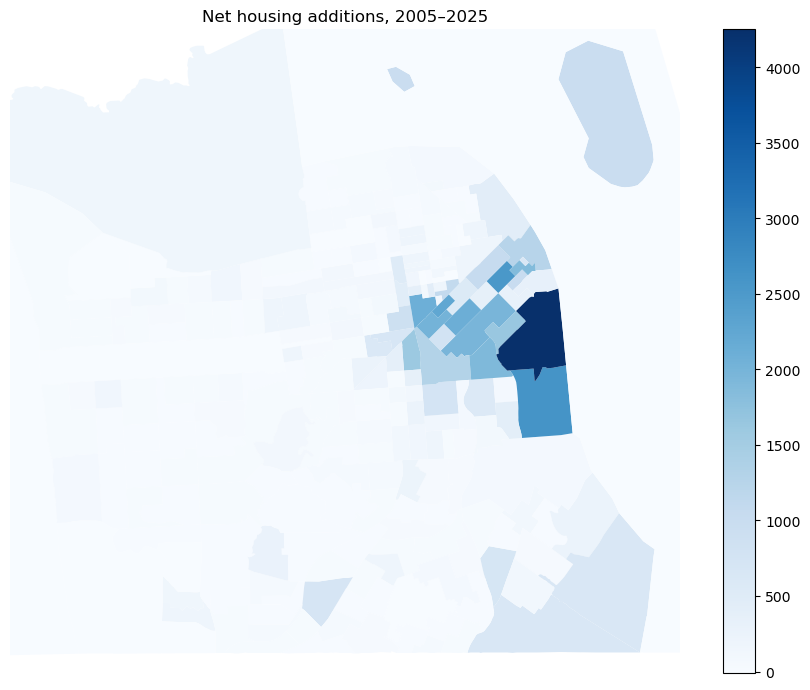

In [63]:
fig, ax = plt.subplots(figsize=(9, 7))
tract_production.plot(column="net_units_added_2005_2025", cmap="Blues", legend=True, ax=ax)
ax.set_xlim(-122.525, -122.35)
ax.set_ylim(37.704, 37.837)
ax.set_axis_off()
ax.set_title("Net housing additions, 2005–2025")
plt.tight_layout()
fig.savefig("visualizations/historical_net_additions_map.png", dpi=200, bbox_inches="tight")
plt.show()


<a id="step-6"></a>
## Step 6 — Classify tracts using 2020–2024 ACS conditions

Read the raw 2024 ACS five-year B19013 and B25003 summary files. Select San Francisco tract rows and retain the 11-character GEOID as text. These estimates describe 2020–2024. Treat negative Census special codes as missing. The income value 250001 means $250,000 or more; retain that flag and use the lower bound of 250000 for grouping. Renter share is renter-occupied units divided by occupied units, excluding vacant units and invalid or zero denominators. Join by GEOID; no spatial join is needed.


In [67]:
income = pd.read_csv("data/raw/acs2024_b19013.dat", sep="|", dtype={"GEO_ID": str})
tenure = pd.read_csv("data/raw/acs2024_b25003.dat", sep="|", dtype={"GEO_ID": str})

# Use the same string slicing and GEOID construction taught in Lab 3 and Lab 6.
for table in [income, tenure]:
    sf_rows = []
    geoid_values = []
    for geo_id in table["GEO_ID"]:
        sf_rows.append(geo_id[:14] == "1400000US06075")
        geoid_values.append(geo_id[-11:])
    table["is_sf"] = sf_rows
    table["GEOID"] = geoid_values
    
income = income.loc[income["is_sf"]].copy()
tenure = tenure.loc[tenure["is_sf"]].copy()


income = income[["GEOID", "B19013_E001", "B19013_M001"]].rename(columns={
    "B19013_E001": "median_income", 
    "B19013_M001": "income_moe90"
})

tenure = tenure[["GEOID", "B25003_E001", "B25003_E003"]].rename(columns={
    "B25003_E001": "occupied_units", 
    "B25003_E003": "renter_occupied_units"
})

income["income_topcoded"] = income["median_income"] == 250001
income.loc[income["median_income"] < 0, "median_income"] = np.nan
income.loc[income["income_moe90"] < 0, "income_moe90"] = np.nan
income.loc[income["income_topcoded"], "median_income"] = 250000


for column in ["occupied_units", "renter_occupied_units"]:
    tenure.loc[tenure[column] < 0, column] = np.nan


valid_tenure = (tenure["occupied_units"] > 0) & (tenure["renter_occupied_units"] >= 0) & (tenure["renter_occupied_units"] <= tenure["occupied_units"])

tenure["renter_share"] = np.nan

tenure.loc[valid_tenure, "renter_share"] = tenure.loc[valid_tenure, "renter_occupied_units"] / tenure.loc[valid_tenure, "occupied_units"]
master = tract_production.merge(income, on="GEOID", how="left").merge(tenure, on="GEOID", how="left")


### 6b. Use one common sample and assign income/renter-share terciles

Keep all 244 tracts in the master and use the same 234 tracts with valid income and renter share for both classifications. Compute the one-third and two-thirds quantiles separately for each measure, then assign lower, middle and higher with loc. Each group contains 78 tracts in this dataset. The other ten known tracts are unclassified because of ACS availability, not missing permit locations. These are relative local groups based on 2020–2024 conditions, not official income-eligibility categories or fixed historical neighborhood identities.


In [68]:
master["common_acs_valid"] = (~master["median_income"].isna()) & (~master["renter_share"].isna())
common = master.loc[master["common_acs_valid"]].copy()
group_cutoff_rows = []
for value, group_column in [("median_income", "income_group"), ("renter_share", "renter_group")]:
    lower_cut = common[value].quantile(1 / 3)
    upper_cut = common[value].quantile(2 / 3)
    master[group_column] = "unclassified"
    valid = master["common_acs_valid"]
    master.loc[valid & (master[value] <= lower_cut), group_column] = "lower"
    master.loc[valid & (master[value] > lower_cut) & (master[value] <= upper_cut), group_column] = "middle"
    master.loc[valid & (master[value] > upper_cut), group_column] = "higher"
    group_cutoff_rows.append([group_column, lower_cut, upper_cut, "2020–2024"])
group_cutoffs = pd.DataFrame(group_cutoff_rows, columns=["dimension", "lower_cut", "upper_cut", "acs_period"])
group_cutoffs.to_csv("data/processed/acs_group_cutoffs.csv", index=False)
master.drop(columns="geometry").to_csv("data/processed/tract_acs_groups.csv", index=False)
print("All tracts:", len(master))
print("Common-valid ACS tracts:", len(common))
master.groupby("income_group").size()


All tracts: 244
Common-valid ACS tracts: 234


income_group
higher          78
lower           78
middle          78
unclassified    10
dtype: int64

FileNotFoundError: [Errno 2] No such file or directory: 'visualizations/acs_group_maps.png'

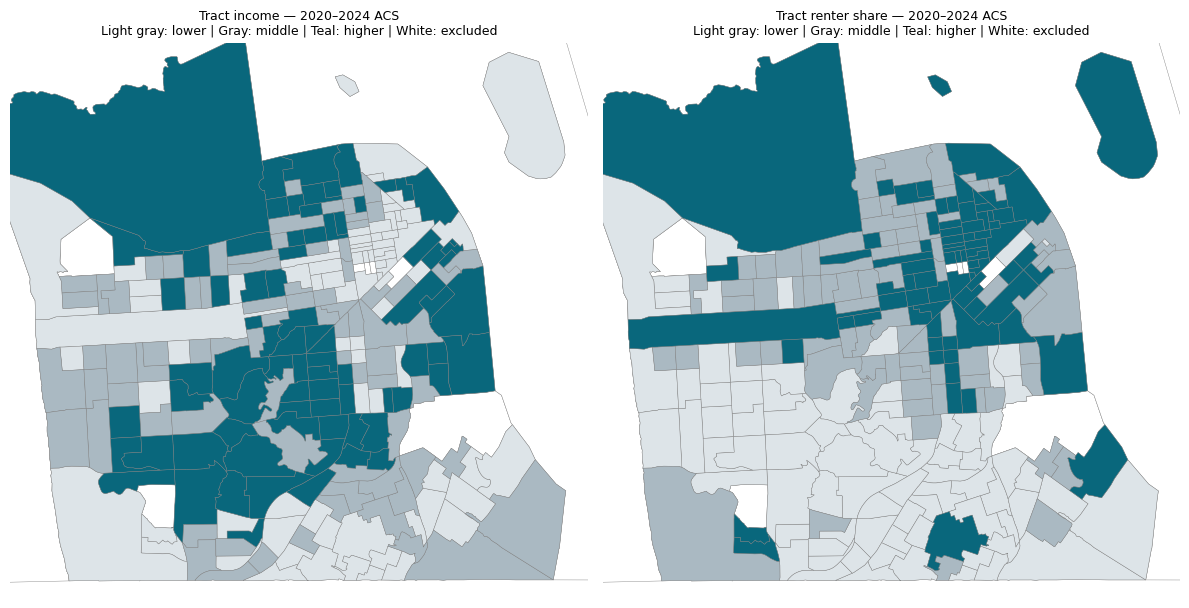

In [69]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, group_column, title in zip(axes, ["income_group", "renter_group"], ["Tract income", "Tract renter share"]):
    master.plot(ax=ax, color="white", edgecolor="gray", linewidth=0.3)
    for group, color in [("lower", "#DDE4E8"), ("middle", "#AAB9C2"), ("higher", "#09677C")]:
        master.loc[master[group_column] == group].plot(ax=ax, color=color, edgecolor="gray", linewidth=0.3)
    ax.set_xlim(-122.525, -122.35)
    ax.set_ylim(37.704, 37.837)
    ax.set_axis_off()
    ax.set_title(title + " — 2020–2024 ACS\nLight gray: lower | Gray: middle | Teal: higher | White: excluded", fontsize=9)
plt.tight_layout()
fig.savefig("visualizations/acs_group_maps.png", dpi=200, bbox_inches="tight")
plt.show()


<a id="step-7"></a>
## Step 7 — Compare historical net additions across recent ACS groups

**更新旧 proposal 的 share comparison。** 我们没有可靠的 2005 住房存量，所以不再比较“2005 存量份额”和“后来新增份额”。改为分别按收入与 renter share 计算：各组净新增总量、占全市源数据净新增的份额、每个 tract 的净新增中位数与均值。

全市份额分母是 Step 1 研究样本的 signed net additions。`unclassified` 是已知 tract 但 ACS 不完整；`unassigned_to_tract` 是没有位置的住房记录。两者分别报告，不混在低收入组里。本版本全部住房都获得 tract，因此后者为零，前者仍有 10 个 tract。

总量回答“住房新增主要集中在哪些组”；中位数回答“典型 tract 有多少净新增”，避免少数大项目完全支配读图。所有比较按 2020–2024 社区特征回看历史，不把这些标签视为 2005 年以来一直不变，也不解释为因果关系。

**English explanation**

Compare total net additions, share of the full citywide net-additions total, median tract additions and mean tract additions for each income and renter-share group. Do not compare against an unsupported 2005 housing-stock share. Separate ACS-unclassified tracts from housing without a tract. Totals describe production concentration; medians describe a typical tract and are less dominated by large projects. The analysis groups historical production by recent community characteristics and does not estimate causal effects.


In [71]:
group_rows = []
group_order = ["lower", "middle", "higher", "unclassified", "unassigned_to_tract"]
for dimension in ["income", "renter"]:
    for group in group_order:
        rows = master.loc[master[dimension + "_group"] == group]
        net_units = rows["net_units_added_2005_2025"].sum()
        records = rows["production_records"].sum()
        median_units = rows["net_units_added_2005_2025"].median()
        mean_units = rows["net_units_added_2005_2025"].mean()
        if group == "unassigned_to_tract":
            net_units = unassigned_net_units
            records = int(detailed["GEOID"].isna().sum())
        share = np.nan
        if city_net_units != 0:
            share = net_units / city_net_units * 100
        group_rows.append([dimension, group, len(rows), records, net_units, share, median_units, mean_units, "2020–2024"])
group_comparison = pd.DataFrame(group_rows, columns=[
    "dimension", "group", "tracts", "production_records", "net_units", "share_city_net_pct",
    "median_tract_net_units", "mean_tract_net_units", "classification_period"
])
group_comparison.to_csv("data/processed/group_housing_comparisons.csv", index=False)
group_comparison


,dimension,group,tracts,production_records,net_units,share_city_net_pct,median_tract_net_units,mean_tract_net_units,classification_period
0,income,lower,78,1580,16154,27.860370,65.5,207.102564,2020–2024
1,income,middle,78,2312,17528,30.230071,37.5,224.717949,2020–2024
2,income,higher,78,2056,22729,39.200097,37.5,291.397436,2020–2024
3,income,unclassified,10,33,1571,2.709462,41.5,157.100000,2020–2024
4,income,unassigned_to_tract,0,0,0,0.000000,NaN,NaN,2020–2024
5,renter,lower,78,2431,7669,13.226519,24.5,98.320513,2020–2024
6,renter,middle,78,2098,20191,34.822876,50.0,258.858974,2020–2024
7,renter,higher,78,1419,28551,49.241144,113.5,366.038462,2020–2024
8,renter,unclassified,10,33,1571,2.709462,41.5,157.100000,2020–2024
9,renter,unassigned_to_tract,0,0,0,0.000000,NaN,NaN,2020–2024


FileNotFoundError: [Errno 2] No such file or directory: 'visualizations/group_net_additions.png'

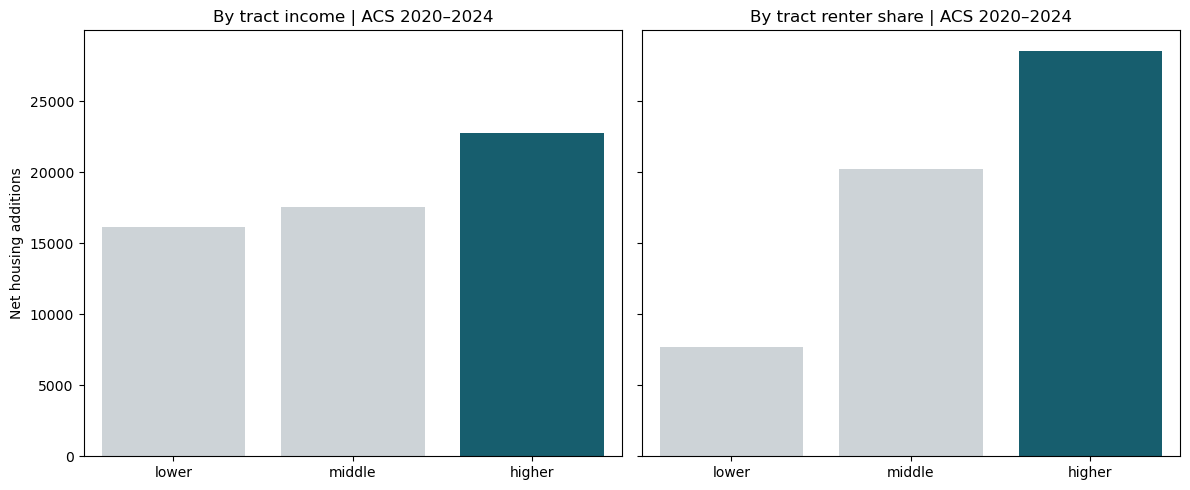

In [72]:
# Use small multiples and the same chart type for both ACS dimensions.
for value, ylabel, filename in [
    ("net_units", "Net housing additions", "group_net_additions.png"),
    ("median_tract_net_units", "Median net additions per tract", "group_median_net_additions.png")
]:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
    for ax, dimension, title in zip(axes, ["income", "renter"], ["By tract income", "By tract renter share"]):
        table = group_comparison.loc[(group_comparison["dimension"] == dimension) & group_comparison["group"].isin(["lower", "middle", "higher"])]
        for group, color in [("lower", "#CBD3D9"), ("middle", "#CBD3D9"), ("higher", "#09677C")]:
            sns.barplot(data=table.loc[table["group"] == group], x="group", y=value,
                        order=["lower", "middle", "higher"], color=color, ax=ax)
        ax.set_title(title + " | ACS 2020–2024")
        ax.set_xlabel("")
        ax.set_ylabel(ylabel)
    plt.tight_layout()
    fig.savefig("visualizations/" + filename, dpi=200, bbox_inches="tight")
    plt.show()
